# ShipRocket Audio Turn Detection

This notebook trains a whisper tiny + cnn classification head model to detect when a person has finished speaking or not.

**Easy summary of how it works:**
1. It downloads the dataset piece by piece (not all at once), so the computer doesn't run out of memory.
2. It picks 20,000 Hindi and 20,000 English audio clips.
3. It only loads the heavy AI tools (PyTorch) *after* the data is ready, to avoid crashes.
4. Then it trains a small speech model (Whisper-tiny) to detect the end of a turn in conversation.

Sets up the basic settings for the whole notebook — like the dataset name, which languages to use (Hindi and English), how many samples to collect, and where to save files.

In [ ]:
import os
import sys
import json
import random
import shutil
import gc
from pathlib import Path

SEED = 42

DATASET_ID = "pipecat-ai/smart-turn-data-v3.2-train"

# Target subset
PER_LANGUAGE_CAP = 20_000
LANGUAGES = ("hin", "eng")

TARGET_SR = 16_000
FIXED_WINDOW_SECONDS = 8.0

# Local working directory
WORK_DIR = Path("/content/smart_turn")
AUDIO_DIR = WORK_DIR / "audio"
CACHE_DIR = WORK_DIR / "cache"
CHECKPOINT_DIR = WORK_DIR / "checkpoints"

for p in [WORK_DIR, AUDIO_DIR, CACHE_DIR, CHECKPOINT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

MANIFEST_PATH = WORK_DIR / "manifest.jsonl"
STATE_PATH = WORK_DIR / "selection_state.json"

# Training
BATCH_SIZE = 16
GRAD_ACCUM_STEPS = 2
EPOCHS = 3
LR = 3e-5
AUX_WEIGHT = 0.2
FOCAL_GAMMA = 2.0

NUM_WORKERS = 0

random.seed(SEED)
print("Python:", sys.version)
print("Work dir:", WORK_DIR)
print("Target:", {x: PER_LANGUAGE_CAP for x in LANGUAGES})


Python: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
Work dir: /content/smart_turn
Target: {'hin': 20000, 'eng': 20000}


In [ ]:
!pip -q install -U huggingface_hub pyarrow soundfile librosa pandas scikit-learn tqdm


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 793.2/793.2 kB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.6/294.6 kB 25.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 119.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 113.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 8.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.5 which is incompatible.
dask-cudf-cu12 26.2.1 requires panda

Checks how much free disk space and memory (RAM) the computer has, before we start downloading anything big.

In [ ]:
!df -h /content
!echo "----- RAM -----"
!free -h
!echo "----- SHM -----"
!df -h /dev/shm


Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   48G   66G  43% /
----- RAM -----
               total        used        free      shared  buff/cache   available
Mem:            12Gi       4.4Gi       1.9Gi       3.0Mi       6.4Gi       8.0Gi
Swap:             0B          0B          0B
----- SHM -----
Filesystem      Size  Used Avail Use% Mounted on
shm             5.7G     0  5.7G   0% /dev/shm


## Dataset acquisition

The public dataset is Parquet-backed and has one `train` split. The Hub page reports roughly 270,946 rows and 41.4 GB total. citeturn0search0

We deliberately avoid `load_dataset(..., streaming=True)` during this stage because that path is what triggered your `torch/storage.py -> _share_fd_cpu_ -> Cannot allocate memory` error.


Looks at the dataset online and makes a list of all its data files (called "Parquet shards") that we can download one at a time.

In [ ]:
from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_files(
    repo_id=DATASET_ID,
    repo_type="dataset",
)

parquet_files = sorted(
    f for f in files
    if f.startswith("data/") and f.endswith(".parquet")
)

print("Parquet shards:", len(parquet_files))
print("First 10:")
for f in parquet_files[:10]:
    print(" ", f)

assert parquet_files, "No Parquet files were found."


Parquet shards: 83
First 10:
  data/train-00000-of-00083.parquet
  data/train-00001-of-00083.parquet
  data/train-00002-of-00083.parquet
  data/train-00003-of-00083.parquet
  data/train-00004-of-00083.parquet
  data/train-00005-of-00083.parquet
  data/train-00006-of-00083.parquet
  data/train-00007-of-00083.parquet
  data/train-00008-of-00083.parquet
  data/train-00009-of-00083.parquet


In [ ]:
!pip uninstall -y pyarrow pandas
!pip install -U pyarrow pandas

Found existing installation: pyarrow 25.0.1
Uninstalling pyarrow-25.0.1:
  Successfully uninstalled pyarrow-25.0.1
Found existing installation: pandas 3.0.5
Uninstalling pandas-3.0.5:
  Successfully uninstalled pandas-3.0.5
  Using cached pyarrow-25.0.1-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (3.0 kB)
  Using cached pandas-3.0.5-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (79 kB)
Using cached pyarrow-25.0.1-cp313-cp313-manylinux_2_28_x86_64.whl (50.1 MB)
Using cached pandas-3.0.5-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl (10.9 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.5 which is incompatible.
dask-cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.5 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, 

In [ ]:
import pyarrow
import pandas
import pyarrow.parquet as pq

print("PyArrow:", pyarrow.__version__)
print("Pandas:", pandas.__version__)
print("PyArrow/Pandas OK")

PyArrow: 25.0.1
Pandas: 3.0.5
PyArrow/Pandas OK


Downloads one data file (shard) from the dataset at a time, so we don't run out of memory.

In [ ]:
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download, HfApi

api = HfApi()
files = api.list_repo_files(
    repo_id=DATASET_ID,
    repo_type="dataset",
)
parquet_files = sorted(
    f for f in files
    if f.startswith("data/") and f.endswith(".parquet")
)

test_file = parquet_files[0]

test_local = hf_hub_download(
    repo_id=DATASET_ID,
    filename=test_file,
    repo_type="dataset",
    local_dir=str(WORK_DIR / "shards"),
)

pf = pq.ParquetFile(test_local);

print("File:", test_file)
print("Rows:", pf.metadata.num_rows)
print()
print(pf.schema_arrow)

print("\nRow groups:", pf.num_row_groups)
for i in range(min(3, pf.num_row_groups)):
    print(
        "row_group", i,
        "rows=", pf.metadata.row_group(i).num_rows
    )


data/train-00000-of-00083.parquet: reconstructing file:   0%|          |  0.00B /  497MB            

data/train-00000-of-00083.parquet: downloading bytes:           |  0.00B            

File: data/train-00000-of-00083.parquet
Rows: 3265

audio: struct<bytes: binary, path: string>
  child 0, bytes: binary
  child 1, path: string
id: string
language: string
endpoint_bool: bool
midfiller: bool
endfiller: bool
synthetic: bool
spoken_text: null
dataset: string
-- schema metadata --
huggingface: '{"info": {"features": {"audio": {"_type": "Audio"}, "id": {' + 396

Row groups: 33
row_group 0 rows= 100
row_group 1 rows= 100
row_group 2 rows= 100


Defines helper functions that pull the actual audio (sound) out of the dataset rows and turn it into a usable format.

In [ ]:
import io
import wave
import soundfile as sf
import numpy as np

def audio_value_to_bytes(audio_value):
    """Return embedded audio bytes when the Parquet audio field contains them."""
    if audio_value is None:
        return None

    if isinstance(audio_value, dict):
        b = audio_value.get("bytes")
        if b is not None:
            return bytes(b)

        # Some Arrow/Python representations use a path instead.
        return None

    if isinstance(audio_value, (bytes, bytearray, memoryview)):
        return bytes(audio_value)

    return None


def decode_audio_bytes(audio_bytes):
    """Decode common audio containers using soundfile."""
    data, sr = sf.read(
        io.BytesIO(audio_bytes),
        dtype="float32",
        always_2d=False,
    )

    if data.ndim == 2:
        data = data.mean(axis=1)

    return np.asarray(data, dtype=np.float32), int(sr)


def resample_audio(y, src_sr, dst_sr=TARGET_SR):
    if src_sr == dst_sr:
        return y.astype(np.float32, copy=False)

    import librosa
    return librosa.resample(
        y.astype(np.float32),
        orig_sr=src_sr,
        target_sr=dst_sr,
    ).astype(np.float32)


def prepare_fixed_window(y, sr=TARGET_SR, seconds=FIXED_WINDOW_SECONDS):
    y = np.asarray(y, dtype=np.float32)

    n = int(sr * seconds)

    if len(y) > n:
        # Preserve the most recent speech, matching the original notebook.
        y = y[-n:]
    elif len(y) < n:
        y = np.pad(y, (n - len(y), 0))

    peak = float(np.max(np.abs(y))) if len(y) else 0.0
    if peak > 0:
        y = y / peak * 0.85

    return y.astype(np.float32)


def write_wav(path, y, sr=TARGET_SR):
    sf.write(
        str(path),
        y.astype(np.float32),
        sr,
        subtype="PCM_16",
    )


 The main data-collection step. It goes through the dataset shard by shard, picks 20,000 Hindi and 20,000 English audio samples, saves them as files, and keeps track of progress so it can resume if it stops partway.

In [ ]:
from tqdm.auto import tqdm
import pyarrow as pa
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download

counts = {lang: 0 for lang in LANGUAGES}
selected = 0

# Resume existing manifest.
if MANIFEST_PATH.exists():
    with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            rec = json.loads(line)
            lang = rec["language"]
            if lang in counts:
                counts[lang] += 1

print("Existing manifest counts:", counts)

def manifest_has_id(example_id):
    return example_id in existing_ids

existing_ids = set()
if MANIFEST_PATH.exists():
    with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                existing_ids.add(json.loads(line)["id"])

print("Existing IDs:", len(existing_ids))

for shard_num, shard_name in enumerate(parquet_files, start=1):

    if all(counts[x] >= PER_LANGUAGE_CAP for x in LANGUAGES):
        break

    print(
        f"\n===== SHARD {shard_num}/{len(parquet_files)} ====="
    )
    print(shard_name)
    print("Current:", counts)

    shard_path = hf_hub_download(
        repo_id=DATASET_ID,
        filename=shard_name,
        repo_type="dataset",
        local_dir=str(WORK_DIR / "shards"),
    )

    try:
        pf = pq.ParquetFile(shard_path)

        # Process row groups one at a time to keep RAM bounded.
        for rg in range(pf.num_row_groups):

            if all(counts[x] >= PER_LANGUAGE_CAP for x in LANGUAGES):
                break

            table = pf.read_row_group(rg)
            records = table.to_pylist()

            for row in records:

                lang = row.get("language")

                if lang not in counts:
                    continue

                if counts[lang] >= PER_LANGUAGE_CAP:
                    continue

                example_id = str(row["id"])

                if example_id in existing_ids:
                    continue

                audio_bytes = audio_value_to_bytes(row.get("audio"))

                if audio_bytes is None:
                    raise RuntimeError(
                        "The dataset audio field was not embedded as bytes "
                        f"in Parquet row {example_id}. "
                        "Run Cell 5 and inspect the audio schema."
                    )

                try:
                    y, sr = decode_audio_bytes(audio_bytes)
                    y = resample_audio(y, sr, TARGET_SR)
                    y = prepare_fixed_window(y)

                    audio_path = AUDIO_DIR / f"{example_id}.wav"
                    write_wav(audio_path, y, TARGET_SR)

                except Exception as e:
                    print(
                        f"Skipping bad audio {example_id}: {type(e).__name__}: {e}"
                    )
                    continue

                record = {
                    "id": example_id,
                    "audio_path": str(audio_path),
                    "language": lang,
                    "endpoint_bool": bool(row.get("endpoint_bool")),
                    "midfiller": (
                        None if row.get("midfiller") is None
                        else bool(row.get("midfiller"))
                    ),
                    "endfiller": (
                        None if row.get("endfiller") is None
                        else bool(row.get("endfiller"))
                    ),
                    "synthetic": (
                        None if row.get("synthetic") is None
                        else bool(row.get("synthetic"))
                    ),
                    "spoken_text": row.get("spoken_text"),
                    "dataset": row.get("dataset"),
                }

                with open(MANIFEST_PATH, "a", encoding="utf-8") as f:
                    f.write(json.dumps(record, ensure_ascii=False) + "\n")

                existing_ids.add(example_id)
                counts[lang] += 1
                selected += 1

                total = sum(counts.values())

                if total % 500 == 0:
                    print(
                        f"selected={total:,} | "
                        f"hin={counts['hin']:,} | "
                        f"eng={counts['eng']:,}"
                    )

                if all(
                    counts[x] >= PER_LANGUAGE_CAP
                    for x in LANGUAGES
                ):
                    break

    finally:
        # Remove local shard copy. The Hugging Face cache may still retain
        # its cached object; this deletion keeps the working directory small.
        try:
            os.remove(shard_path)
        except Exception:
            pass

    gc.collect()

print("\n========================================")
print("SELECTION COMPLETE / CURRENT STATE")
print("========================================")
print("Hindi  :", counts["hin"])
print("English:", counts["eng"])
print("Total  :", sum(counts.values()))
print("Manifest:", MANIFEST_PATH)


Existing manifest counts: {'hin': 0, 'eng': 0}
Existing IDs: 0

===== SHARD 1/83 =====
data/train-00000-of-00083.parquet
Current: {'hin': 0, 'eng': 0}
selected=500 | hin=80 | eng=420

===== SHARD 2/83 =====
data/train-00001-of-00083.parquet
Current: {'hin': 157, 'eng': 804}


data/train-00001-of-00083.parquet: reconstructing file:   0%|          |  0.00B /  496MB            

data/train-00001-of-00083.parquet: downloading bytes:           |  0.00B            

selected=1,000 | hin=161 | eng=839
selected=1,500 | hin=255 | eng=1,245

===== SHARD 3/83 =====
data/train-00002-of-00083.parquet
Current: {'hin': 317, 'eng': 1557}


data/train-00002-of-00083.parquet: reconstructing file:   0%|          |  0.00B /  498MB            

data/train-00002-of-00083.parquet: downloading bytes:           |  0.00B            

... (237 outputs left out)


===== SHARD 83/83 =====
data/train-00082-of-00083.parquet
Current: {'hin': 11883, 'eng': 20000}


data/train-00082-of-00083.parquet: reconstructing file:   0%|          |  0.00B /  493MB            

data/train-00082-of-00083.parquet: downloading bytes:           |  0.00B            

selected=32,000 | hin=12,000 | eng=20,000

SELECTION COMPLETE / CURRENT STATE
Hindi  : 12006
English: 20000
Total  : 32006
Manifest: /content/smart_turn/manifest.jsonl


 Loads the list of collected audio samples (the "manifest") into a table so we can see how many samples we have per language.

In [ ]:
import pandas as pd

manifest_df = pd.read_json(
    MANIFEST_PATH,
    lines=True,
)

print(manifest_df.shape)
print(manifest_df["language"].value_counts())
print()
print(manifest_df["endpoint_bool"].value_counts())

assert len(manifest_df) > 0, (
    f"Expected 40,000 rows, found {len(manifest_df)}. "
    "If extraction stopped early, rerun Cell 7 to resume."
)


(32006, 9)
language
eng    20000
hin    12006
Name: count, dtype: int64

endpoint_bool
False    16106
True     15900
Name: count, dtype: int64


Splits all the collected samples into three groups: one for training the model, one for checking it during training (validation), and one for a final test.

In [ ]:
from sklearn.model_selection import train_test_split

manifest_df["_strat"] = (
    manifest_df["language"].astype(str)
    + "_"
    + manifest_df["endpoint_bool"].astype(int).astype(str)
)

train_df, temp_df = train_test_split(
    manifest_df,
    test_size=0.20,
    random_state=SEED,
    stratify=manifest_df["_strat"],
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["_strat"],
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(
    f"train={len(train_df):,} "
    f"val={len(val_df):,} "
    f"test={len(test_df):,}"
)

print("\nTrain language:")
print(train_df["language"].value_counts())

print("\nTrain endpoint rate:")
print(train_df["endpoint_bool"].mean())


train=25,604 val=3,201 test=3,201

Train language:
language
eng    15999
hin     9605
Name: count, dtype: int64

Train endpoint rate:
0.49679737541009217


Calculates simple numeric features from each audio clip, like pitch and speaking pattern, which help the model understand speech better.

In [ ]:
import librosa

def _f0_slope(y, sr=TARGET_SR, frame_len=2048, hop=512):
    try:
        frames = librosa.util.frame(
            y,
            frame_length=frame_len,
            hop_length=hop,
        )

        if frames.shape[1] < 10:
            return 0.0

        frames = frames - frames.mean(
            axis=0,
            keepdims=True,
        )

        fmin_lag = max(1, int(sr / 1100))
        fmax_lag = min(
            frame_len - 1,
            int(sr / 65),
        )

        Fx = np.fft.rfft(
            frames,
            n=2 * frame_len,
            axis=0,
        )

        ac_full = np.fft.irfft(
            Fx * np.conj(Fx),
            axis=0,
        )[:frame_len]

        ac = ac_full[fmin_lag:fmax_lag]

        if ac.size == 0:
            return 0.0

        max_power = np.abs(frames).max(axis=0)
        ac_power = ac.max(axis=0)

        valid = (
            (max_power > 1e-4)
            & (ac_power > 1e-6)
        )

        if valid.sum() < 10:
            return 0.0

        peak_lags = ac[:, valid].argmax(axis=0)
        f0 = sr / (
            peak_lags.astype(np.float32)
            + fmin_lag
        )

        first = float(f0[:5].mean())
        last = float(f0[-5:].mean())

        return float(
            np.clip(
                (last - first) / (first + 1e-8),
                -5.0,
                5.0,
            )
        )

    except Exception:
        return 0.0


def compute_scalar_features(y, sr=TARGET_SR):
    out = np.array(
        [0.0, 0.0, 1.0, 0.0, 0.0],
        dtype=np.float32,
    )

    try:
        onset = librosa.onset.onset_strength(
            y=y,
            sr=sr,
        )

        if len(onset):
            out[0] = float(onset[:10].max())

        rms = librosa.feature.rms(
            y=y,
            hop_length=160,
        )[0]

        if len(rms) > 10:
            mean_rms = float(rms.mean()) + 1e-8
            out[1] = mean_rms
            out[2] = float(
                rms[-10:].mean()
                / mean_rms
            )

        out[3] = _f0_slope(y, sr)

        out[4] = float(
            np.mean(np.abs(y) > 0.01)
        )

    except Exception:
        pass

    return out


def build_scalar_cache(df, path):
    path = Path(path)

    if path.exists():
        arr = np.load(path)
        if arr.shape == (len(df), 5):
            print("Loaded:", path, arr.shape)
            return arr

    result = np.empty(
        (len(df), 5),
        dtype=np.float32,
    )

    for i, audio_path in enumerate(
        tqdm(df["audio_path"], desc=path.stem)
    ):
        y, sr = sf.read(
            audio_path,
            dtype="float32",
        )

        if y.ndim == 2:
            y = y.mean(axis=1)

        if sr != TARGET_SR:
            y = resample_audio(
                y,
                sr,
                TARGET_SR,
            )

        y = prepare_fixed_window(y)
        result[i] = compute_scalar_features(y)

    np.save(path, result)
    print("Saved:", path, result.shape)

    return result


Runs the feature calculation from the previous cell on the training, validation, and test sets, and saves the results so they don't need to be recalculated later.

In [ ]:
train_scalars = build_scalar_cache(
    train_df,
    CACHE_DIR / "train_scalars.npy",
)

val_scalars = build_scalar_cache(
    val_df,
    CACHE_DIR / "val_scalars.npy",
)

test_scalars = build_scalar_cache(
    test_df,
    CACHE_DIR / "test_scalars.npy",
)

print(
    train_scalars.shape,
    val_scalars.shape,
    test_scalars.shape,
)


train_scalars:   0%|          | 0/25604 [00:00<?, ?it/s]

Saved: /content/smart_turn/cache/train_scalars.npy (25604, 5)


val_scalars:   0%|          | 0/3201 [00:00<?, ?it/s]

Saved: /content/smart_turn/cache/val_scalars.npy (3201, 5)


test_scalars:   0%|          | 0/3201 [00:00<?, ?it/s]

Saved: /content/smart_turn/cache/test_scalars.npy (3201, 5)
(25604, 5) (3201, 5) (3201, 5)


## PyTorch / Whisper stage


In [ ]:
!pip -q install -U transformers accelerate evaluate


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 80.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.9 MB/s eta 0:00:00


Loads PyTorch and the Whisper speech model, plus tools to measure how well the model performs.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset as TorchDataset
from torch.utils.data import DataLoader

from transformers import (
    WhisperModel,
    WhisperFeatureExtractor,
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
)

import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2,
        ),
        "GB",
    )
else:
    raise RuntimeError(
        "A GPU is required for this notebook. "
        "In Colab choose Runtime -> Change runtime type -> T4 GPU."
    )


PyTorch: 2.11.0+cu128
CUDA: True
Device: cuda
GPU: Tesla T4
VRAM: 14.56 GB


Prepares the saved audio files so they can be fed into the model in batches during training.

In [ ]:
feature_extractor = WhisperFeatureExtractor.from_pretrained(
    "openai/whisper-tiny"
)

class TurnDataset(TorchDataset):
    def __init__(self, df, scalar_cache):
        self.df = df.reset_index(drop=True)
        self.scalar_cache = scalar_cache

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        y, sr = sf.read(
            row["audio_path"],
            dtype="float32",
        )

        if y.ndim == 2:
            y = y.mean(axis=1)

        y = prepare_fixed_window(
            y,
            sr=TARGET_SR,
        )

        features = feature_extractor(
            y,
            sampling_rate=TARGET_SR,
            return_tensors="pt",
        )["input_features"][0]

        return {
            "input_features": features,
            "scalar_features": torch.tensor(
                self.scalar_cache[idx],
                dtype=torch.float32,
            ),
            "endpoint_label": float(
                row["endpoint_bool"]
            ),
            "midfiller_label": (
                0.0 if pd.isna(row["midfiller"])
                else float(row["midfiller"])
            ),
            "endfiller_label": (
                0.0 if pd.isna(row["endfiller"])
                else float(row["endfiller"])
            ),
            "language": row["language"],
        }


def collate(batch):
    return {
        "input_features": torch.stack(
            [x["input_features"] for x in batch]
        ),
        "scalar_features": torch.stack(
            [x["scalar_features"] for x in batch]
        ),
        "endpoint_labels": torch.tensor(
            [x["endpoint_label"] for x in batch],
            dtype=torch.float32,
        ),
        "midfiller_labels": torch.tensor(
            [x["midfiller_label"] for x in batch],
            dtype=torch.float32,
        ),
        "endfiller_labels": torch.tensor(
            [x["endfiller_label"] for x in batch],
            dtype=torch.float32,
        ),
        "languages": [
            x["language"] for x in batch
        ],
    }


train_torch_ds = TurnDataset(
    train_df,
    train_scalars,
)

val_torch_ds = TurnDataset(
    val_df,
    val_scalars,
)

test_torch_ds = TurnDataset(
    test_df,
    test_scalars,
)

train_loader = DataLoader(
    train_torch_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate,
)

val_loader = DataLoader(
    val_torch_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate,
)

test_loader = DataLoader(
    test_torch_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate,
)

print("Loaders ready.")


preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

Loaders ready.


Defines the actual model architecture — the neural network that will learn to detect when someone has finished speaking.

In [ ]:
ENCODER_DIM = 384
GLOBAL_DIM = 128
TAIL_DIM = 64
SCALAR_DIM = 32
NUM_SCALAR_FEATURES = 5
N_UNFROZEN_ENCODER_LAYERS = 2

# Whisper tiny encoder outputs 1500 time positions for 8 sec
ENCODER_FRAMES_PER_SECOND = 50
VALID_ENCODER_FRAMES = 400
TURN_END_FRAMES = 100


class AttentionPool(nn.Module):
    def __init__(self, input_dim, hidden_dim=64):
        super().__init__()

        self.attn = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):
        weights = F.softmax(
            self.attn(x),
            dim=1,
        )
        return (x * weights).sum(dim=1)


class WhisperTurnDetector(nn.Module):

    def __init__(
        self,
        whisper_model_id="openai/whisper-tiny",
        n_unfrozen_encoder_layers=2,
        turn_end_frames=100,
        dropout=0.1,
    ):
        super().__init__()

        whisper = WhisperModel.from_pretrained(
            whisper_model_id
        )

        self.encoder = whisper.encoder
        del whisper

        self.turn_end_frames = turn_end_frames

        # Freeze Whisper first.
        for p in self.encoder.parameters():
            p.requires_grad = False

        # Unfreeze only the final encoder layers.
        n_layers = len(self.encoder.layers)

        for layer in self.encoder.layers[
            max(0, n_layers - n_unfrozen_encoder_layers):
        ]:
            for p in layer.parameters():
                p.requires_grad = True

        for p in self.encoder.layer_norm.parameters():
            p.requires_grad = True

        self.global_cnn = nn.Sequential(
            nn.Conv1d(
                ENCODER_DIM,
                256,
                kernel_size=5,
                padding=2,
            ),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Conv1d(
                256,
                GLOBAL_DIM,
                kernel_size=3,
                padding=1,
            ),
            nn.BatchNorm1d(GLOBAL_DIM),
            nn.GELU(),
            nn.Dropout(dropout),
        )

        self.global_pool = AttentionPool(
            GLOBAL_DIM,
            hidden_dim=64,
        )

        self.tail_cnn = nn.Sequential(
            nn.Conv1d(
                ENCODER_DIM,
                128,
                kernel_size=3,
                padding=1,
            ),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Conv1d(
                128,
                TAIL_DIM,
                kernel_size=3,
                padding=1,
            ),
            nn.BatchNorm1d(TAIL_DIM),
            nn.GELU(),
        )

        self.scalar_proj = nn.Sequential(
            nn.Linear(
                NUM_SCALAR_FEATURES,
                SCALAR_DIM,
            ),
            nn.GELU(),
        )

        combined_dim = (
            GLOBAL_DIM
            + TAIL_DIM
            + SCALAR_DIM
        )

        self.trunk = nn.Sequential(
            nn.Linear(combined_dim, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(dropout * 2),

            nn.Linear(128, 64),
            nn.GELU(),
        )

        self.endpoint_head = nn.Linear(64, 1)
        self.midfiller_head = nn.Linear(64, 1)
        self.endfiller_head = nn.Linear(64, 1)

    def forward(
        self,
        input_features,
        scalar_features,
    ):
        enc = self.encoder(
            input_features
        ).last_hidden_state

        # Global branch
        g = self.global_cnn(
            enc.permute(0, 2, 1)
        )

        g = self.global_pool(
            g.permute(0, 2, 1)
        )

        # Tail branch
        tail_start = (
            VALID_ENCODER_FRAMES
            - self.turn_end_frames
        )

        tail = enc[
            :,
            tail_start:VALID_ENCODER_FRAMES,
            :,
        ]

        t = self.tail_cnn(
            tail.permute(0, 2, 1)
        )

        t = torch.max(t, dim=-1)[0]

        # Scalar branch
        s = self.scalar_proj(
            scalar_features
        )

        combined = torch.cat(
            [g, t, s],
            dim=-1,
        )

        trunk = self.trunk(combined)

        return {
            "endpoint_logits":
                self.endpoint_head(trunk).squeeze(-1),

            "midfiller_logits":
                self.midfiller_head(trunk).squeeze(-1),

            "endfiller_logits":
                self.endfiller_head(trunk).squeeze(-1),
        }


model = WhisperTurnDetector(
    n_unfrozen_encoder_layers=N_UNFROZEN_ENCODER_LAYERS,
    turn_end_frames=TURN_END_FRAMES,
).to(device)

n_total = sum(
    p.numel() for p in model.parameters()
)

n_trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    f"Trainable: {n_trainable:,} / "
    f"{n_total:,} "
    f"({100*n_trainable/n_total:.1f}%)"
)


config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  151MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

Trainable: 4,358,532 / 9,017,988 (48.3%)


Runs one quick test batch through the model just to make sure everything is wired together correctly before real training starts.

In [ ]:
batch = next(iter(train_loader))

with torch.no_grad():
    test_out = model(
        batch["input_features"].to(device),
        batch["scalar_features"].to(device),
    )

print({
    k: tuple(v.shape)
    for k, v in test_out.items()
})

del batch, test_out
torch.cuda.empty_cache()


{'endpoint_logits': (8,), 'midfiller_logits': (8,), 'endfiller_logits': (8,)}


Sets up how the model will learn — the loss function and the optimizer.

In [ ]:
train_pos_rate = float(
    train_df["endpoint_bool"].mean()
)

pos_weight = (
    (1.0 - train_pos_rate)
    / max(train_pos_rate, 1e-8)
)

print("Train positive rate:", train_pos_rate)
print("Positive weight:", pos_weight)


class FocalLoss(nn.Module):
    def __init__(
        self,
        gamma=2.0,
        pos_weight=1.0,
    ):
        super().__init__()

        self.gamma = gamma

        self.register_buffer(
            "pos_weight",
            torch.tensor(
                float(pos_weight),
                dtype=torch.float32,
            ),
        )

    def forward(self, logits, targets):

        bce = F.binary_cross_entropy_with_logits(
            logits,
            targets,
            pos_weight=self.pos_weight,
            reduction="none",
        )

        # Standard focal modulation using the BCE term.
        p_t = torch.exp(-bce)

        loss = (
            (1.0 - p_t) ** self.gamma
        ) * bce

        return loss.mean()


endpoint_loss_fn = FocalLoss(
    gamma=FOCAL_GAMMA,
    pos_weight=pos_weight,
).to(device)

aux_loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    [
        p
        for p in model.parameters()
        if p.requires_grad
    ],
    lr=LR,
    weight_decay=0.01,
)

steps_per_epoch = max(
    1,
    (len(train_loader) + GRAD_ACCUM_STEPS - 1)
    // GRAD_ACCUM_STEPS,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS * steps_per_epoch,
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available(),
)

print("steps/epoch:", steps_per_epoch)


Train positive rate: 0.49679737541009217
Positive weight: 1.0128930817610062
steps/epoch: 1601


The main training loop — this is where the model actually learns from the training data, going through it multiple times (epochs), and saving the best version.

In [ ]:
history = []
best_f1 = -1.0

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    optimizer.zero_grad(set_to_none=True)

    for step, batch in enumerate(
        tqdm(
            train_loader,
            desc=f"Epoch {epoch+1}/{EPOCHS}",
        )
    ):

        feats = batch[
            "input_features"
        ].to(
            device,
            non_blocking=True,
        )

        scalars = batch[
            "scalar_features"
        ].to(
            device,
            non_blocking=True,
        )

        endpoint_labels = batch[
            "endpoint_labels"
        ].to(device)

        midfiller_labels = batch[
            "midfiller_labels"
        ].to(device)

        endfiller_labels = batch[
            "endfiller_labels"
        ].to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=True,
        ):

            out = model(
                feats,
                scalars,
            )

            loss = (
                endpoint_loss_fn(
                    out["endpoint_logits"],
                    endpoint_labels,
                )
                + AUX_WEIGHT
                * aux_loss_fn(
                    out["midfiller_logits"],
                    midfiller_labels,
                )
                + AUX_WEIGHT
                * aux_loss_fn(
                    out["endfiller_logits"],
                    endfiller_labels,
                )
            )

            loss_for_backward = (
                loss / GRAD_ACCUM_STEPS
            )

        scaler.scale(
            loss_for_backward
        ).backward()

        should_step = (
            (step + 1) % GRAD_ACCUM_STEPS == 0
            or (step + 1) == len(train_loader)
        )

        if should_step:

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                1.0,
            )

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(
                set_to_none=True
            )

            scheduler.step()

        running_loss += float(loss.item())

    model.eval()

    preds = []
    labels = []

    with torch.no_grad():

        for batch in tqdm(
            val_loader,
            desc="Validation",
        ):

            feats = batch[
                "input_features"
            ].to(device)

            scalars = batch[
                "scalar_features"
            ].to(device)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
            ):

                out = model(
                    feats,
                    scalars,
                )

            probs = torch.sigmoid(
                out["endpoint_logits"]
            ).float().cpu().numpy()

            preds.extend(
                (probs >= 0.5).astype(int).tolist()
            )

            labels.extend(
                batch[
                    "endpoint_labels"
                ].numpy().astype(int).tolist()
            )

    train_loss = (
        running_loss / len(train_loader)
    )

    val_acc = accuracy_score(
        labels,
        preds,
    )

    val_f1 = f1_score(
        labels,
        preds,
        zero_division=0,
    )

    history.append(
        {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_acc": val_acc,
            "val_f1": val_f1,
        }
    )

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"loss={train_loss:.4f} | "
        f"val_acc={val_acc:.4f} | "
        f"val_f1={val_f1:.4f}"
    )

    if val_f1 > best_f1:

        best_f1 = val_f1

        torch.save(
            model.state_dict(),
            CHECKPOINT_DIR / "best_model.pt",
        )

        print(
            f"  New best F1={best_f1:.4f}"
        )

    gc.collect()
    torch.cuda.empty_cache()


Epoch 1/3:   0%|          | 0/3201 [00:00<?, ?it/s]

Validation:   0%|          | 0/401 [00:00<?, ?it/s]

Epoch 1/3 | loss=0.1794 | val_acc=0.9241 | val_f1=0.9248
  New best F1=0.9248


Epoch 2/3:   0%|          | 0/3201 [00:00<?, ?it/s]

Validation:   0%|          | 0/401 [00:00<?, ?it/s]

Epoch 2/3 | loss=0.0805 | val_acc=0.9306 | val_f1=0.9317
  New best F1=0.9317


Epoch 3/3:   0%|          | 0/3201 [00:00<?, ?it/s]

Validation:   0%|          | 0/401 [00:00<?, ?it/s]

Epoch 3/3 | loss=0.0588 | val_acc=0.9316 | val_f1=0.9318
  New best F1=0.9318


Draws graphs showing how the training went — for example, how the loss/error went down over time.

,epoch,train_loss,val_acc,val_f1
0,1,0.179418,0.924086,0.924791
1,2,0.080535,0.930647,0.931734
2,3,0.058835,0.931584,0.931839


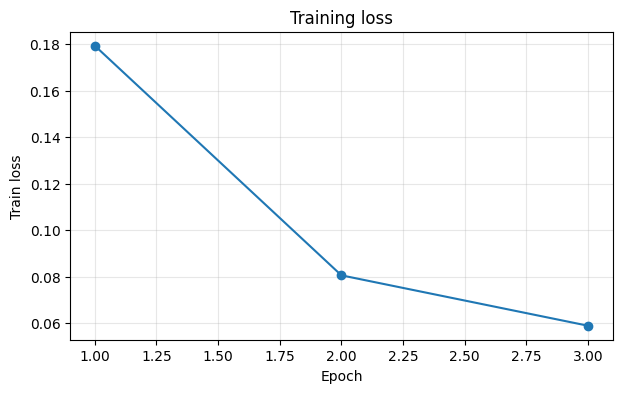

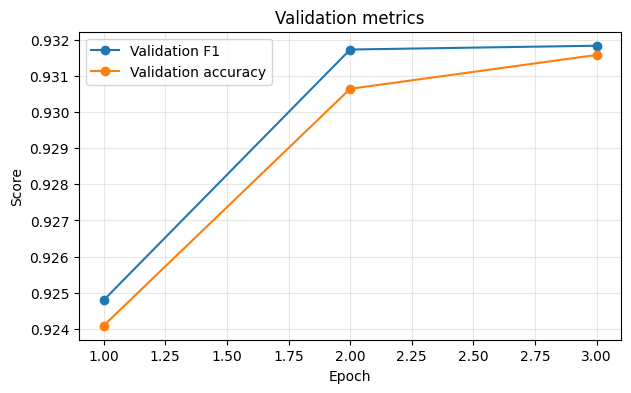

In [ ]:
history_df = pd.DataFrame(history)

display(history_df)

plt.figure(figsize=(7, 4))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
)
plt.xlabel("Epoch")
plt.ylabel("Train loss")
plt.title("Training loss")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(
    history_df["epoch"],
    history_df["val_f1"],
    marker="o",
    label="Validation F1",
)
plt.plot(
    history_df["epoch"],
    history_df["val_acc"],
    marker="o",
    label="Validation accuracy",
)
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation metrics")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


 Loads the best saved model and checks how well it performs on the test data it has never seen before.

In [ ]:
best_path = CHECKPOINT_DIR / "best_model.pt"

if not best_path.exists():
    raise FileNotFoundError(
        f"Checkpoint not found: {best_path}"
    )

state = torch.load(
    best_path,
    map_location=device,
)

model.load_state_dict(state)
model.eval()

all_preds = []
all_labels = []
all_probs = []
all_langs = []

with torch.no_grad():

    for batch in tqdm(
        test_loader,
        desc="Test",
    ):

        feats = batch[
            "input_features"
        ].to(device)

        scalars = batch[
            "scalar_features"
        ].to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):

            out = model(
                feats,
                scalars,
            )

        probs = torch.sigmoid(
            out["endpoint_logits"]
        ).float().cpu().numpy()

        preds = (
            probs >= 0.5
        ).astype(int)

        all_probs.extend(probs.tolist())
        all_preds.extend(preds.tolist())

        all_labels.extend(
            batch[
                "endpoint_labels"
            ].numpy().astype(int).tolist()
        )

        all_langs.extend(
            batch["languages"]
        )

print("================================")
print("OVERALL TEST")
print("================================")

print(
    "Accuracy :",
    accuracy_score(
        all_labels,
        all_preds,
    ),
)

print(
    "F1       :",
    f1_score(
        all_labels,
        all_preds,
        zero_division=0,
    ),
)

print(
    "Precision:",
    precision_score(
        all_labels,
        all_preds,
        zero_division=0,
    ),
)

print(
    "Recall   :",
    recall_score(
        all_labels,
        all_preds,
        zero_division=0,
    ),
)

cm = confusion_matrix(
    all_labels,
    all_preds,
)

print("\nConfusion matrix:")
print(cm)


Test:   0%|          | 0/401 [00:00<?, ?it/s]

OVERALL TEST
Accuracy : 0.9350203061543267
F1       : 0.9354037267080745
Precision: 0.9239263803680982
Recall   : 0.9471698113207547

Confusion matrix:
[[1487  124]
 [  84 1506]]


Shows the test results separately for each language (Hindi and English), so we can see if one language works better than the other.

In [ ]:
all_preds_np = np.asarray(all_preds)
all_labels_np = np.asarray(all_labels)
all_langs_np = np.asarray(all_langs)

for lang in LANGUAGES:

    mask = all_langs_np == lang

    if not mask.any():
        continue

    print(f"\n===== {lang.upper()} =====")

    print(
        "N:",
        int(mask.sum()),
    )

    print(
        "Accuracy:",
        accuracy_score(
            all_labels_np[mask],
            all_preds_np[mask],
        ),
    )

    print(
        "F1:",
        f1_score(
            all_labels_np[mask],
            all_preds_np[mask],
            zero_division=0,
        ),
    )


===== HIN =====
N: 1200
Accuracy: 0.945
F1: 0.9439728353140917

===== ENG =====
N: 2001
Accuracy: 0.9290354822588706
F1: 0.930460333006856


Saves the final trained model, the training history, and the manifest file so everything can be reused later.

In [ ]:
FINAL_DIR = WORK_DIR / "final"
FINAL_DIR.mkdir(exist_ok=True)

torch.save(
    model.state_dict(),
    FINAL_DIR / "smart_turn_whisper_tiny.pt",
)

history_df.to_csv(
    FINAL_DIR / "training_history.csv",
    index=False,
)

manifest_df.drop(
    columns=["_strat"],
    errors="ignore",
).to_csv(
    FINAL_DIR / "manifest.csv",
    index=False,
)

print("Saved:")
for p in sorted(FINAL_DIR.iterdir()):
    print(" ", p)


Saved:
  /content/smart_turn/final/manifest.csv
  /content/smart_turn/final/smart_turn_whisper_tiny.pt
  /content/smart_turn/final/training_history.csv


simple web demo using Gradio. where we can speak into our microphone and the trained model will guess if you've finished talking or not.

In [ ]:
import numpy as np
import torch
import librosa
import gradio as gr


def predict_from_gradio_audio(audio):
    """
    Run the trained Hinglish turn detector on
    microphone/uploaded audio.
    """

    if audio is None:
        return "No audio provided.", ""

    sr, waveform = audio

    # Convert stereo -> mono
    if waveform.ndim > 1:
        waveform = waveform.mean(axis=1)

    # Convert to float32
    waveform = waveform.astype(np.float32)

    # Normalize if audio is in integer-like range
    max_amplitude = np.abs(waveform).max()

    if max_amplitude > 1.0:
        waveform = waveform / (max_amplitude + 1e-8)

    # Resample to the same sample rate used during training
    if sr != TARGET_SR:
        waveform = librosa.resample(
            waveform,
            orig_sr=sr,
            target_sr=TARGET_SR
        )

    # Make the audio compatible with the model
    waveform = prepare_fixed_window(waveform)

    # Extract model features
    feats = feature_extractor(
        waveform,
        sampling_rate=TARGET_SR,
        return_tensors="pt"
    )["input_features"].to(device)

    # Extract scalar features
    scalar_values = compute_scalar_features(waveform)

    scalars = torch.tensor(
        scalar_values,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    # Model inference
    model.eval()

    with torch.no_grad():
        out = model(feats, scalars)

    # Convert logits -> probability
    p = torch.sigmoid(
        out["endpoint_logits"]
    ).item()

    # Decision
    if p >= 0.5:
        verdict = "END OF TURN -- respond now"
    else:
        verdict = "STILL SPEAKING -- keep listening"

    probability = f"P(end of turn) = {p:.3f}"

    return verdict, probability


demo = gr.Interface(
    fn=predict_from_gradio_audio,

    inputs=gr.Audio(
        sources=["microphone", "upload"],
        type="numpy",
        label="Speak or upload audio"
    ),

    outputs=[
        gr.Textbox(label="Verdict"),
        gr.Textbox(label="Probability")
    ],

    title="Hinglish Turn Detector v2",
    description="Record speech or upload an audio file to detect whether the speaker has finished their turn."
)


demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f2e565c8268fb66889.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
